# Variable-aerodynamics model and uncertainty

Fits the launch velocity to both measured positions under drag-only and drag-plus-assumed-Magnus dynamics. The 5 mm coordinate noise is an assumption; the Monte Carlo intervals propagate only that measurement noise. Spin/drag sweeps are illustrative scenarios, not probability intervals or real-world validation.


MODEL FITS TO THE TWO OBSERVED POSITIONS
Fitting 3 launch-velocity components; initial position is treated as exact.
Fit diagnostic tests the observations against the assumed 5 mm noise; it is not real-world validation.

Drag only:
  Fitted launch velocity: [30.0713  8.7948  6.887 ] m/s
  Observed - fitted residuals (mm):
[[ 7.39 13.47  0.36]
 [-3.76 -6.79 -0.19]]
  Coordinate RMSE: 7.03 mm (assumed sigma = 5.0 mm)
  Noise-only fit diagnostic: chi-square=11.86, dof=3, p=0.0079
  Flag: residuals are larger than expected from 5 mm Gaussian measurement noise alone.
  Exact goal crossing: t=0.38610 s, y=3.217 m, z=1.923 m



Drag + Magnus (assumed spin):
  Fitted launch velocity: [30.0733  8.786   6.8894] m/s
  Observed - fitted residuals (mm):
[[ 7.35 13.66  0.31]
 [-3.74 -6.89 -0.16]]
  Coordinate RMSE: 7.10 mm (assumed sigma = 5.0 mm)
  Noise-only fit diagnostic: chi-square=12.09, dof=3, p=0.0071
  Flag: residuals are larger than expected from 5 mm Gaussian measurement noise alone.
  Exact goal crossing: t=0.38620 s, y=3.229 m, z=1.921 m



SYNTHETIC RECOVERY (self-consistency only)
  Launch-velocity recovery error: 3.97205e-15 m/s
  Crossing recovery error: dy=-8.88178e-16 m, dz=-2.22045e-16 m

500-TRIAL MEASUREMENT-NOISE PROPAGATION (sigma=5.0 mm)



Drag only:
  Flight time mean +/- SD: 0.3861 +/- 0.0006 s
  Y mean +/- SD: 3.217 +/- 0.017 m
  Z mean +/- SD: 1.923 +/- 0.017 m
  Empirical 95% interval Y: [3.182, 3.249] m
  Empirical 95% interval Z: [1.887, 1.955] m



Drag + Magnus (assumed spin):
  Flight time mean +/- SD: 0.3862 +/- 0.0006 s
  Y mean +/- SD: 3.229 +/- 0.017 m
  Z mean +/- SD: 1.920 +/- 0.017 m
  Empirical 95% interval Y: [3.197, 3.264] m
  Empirical 95% interval Z: [1.889, 1.952] m

PARAMETER SENSITIVITY (illustrative assumptions, not a confidence interval)
Spin x | Drag x | Fit RMSE mm | Time s | Goal y m | Goal z m
   0.0 |    0.8 |        7.63 | 0.3829 |    3.217 |    1.930
   0.0 |    1.0 |        7.03 | 0.3861 |    3.217 |    1.923


   0.0 |    1.2 |        6.48 | 0.3893 |    3.217 |    1.916
   0.5 |    0.8 |        7.65 | 0.3829 |    3.220 |    1.930


... (4 outputs left out)

   1.5 |    1.0 |        7.18 | 0.3863 |    3.243 |    1.917


   1.5 |    1.2 |        6.64 | 0.3896 |    3.243 |    1.910


   2.0 |    0.8 |        7.87 | 0.3833 |    3.261 |    1.920
   2.0 |    1.0 |        7.29 | 0.3865 |    3.261 |    1.913


   2.0 |    1.2 |        6.76 | 0.3897 |    3.262 |    1.906
Scenario envelope (not probabilistic):
  Y: [3.217, 3.262] m
  Z: [1.906, 1.930] m


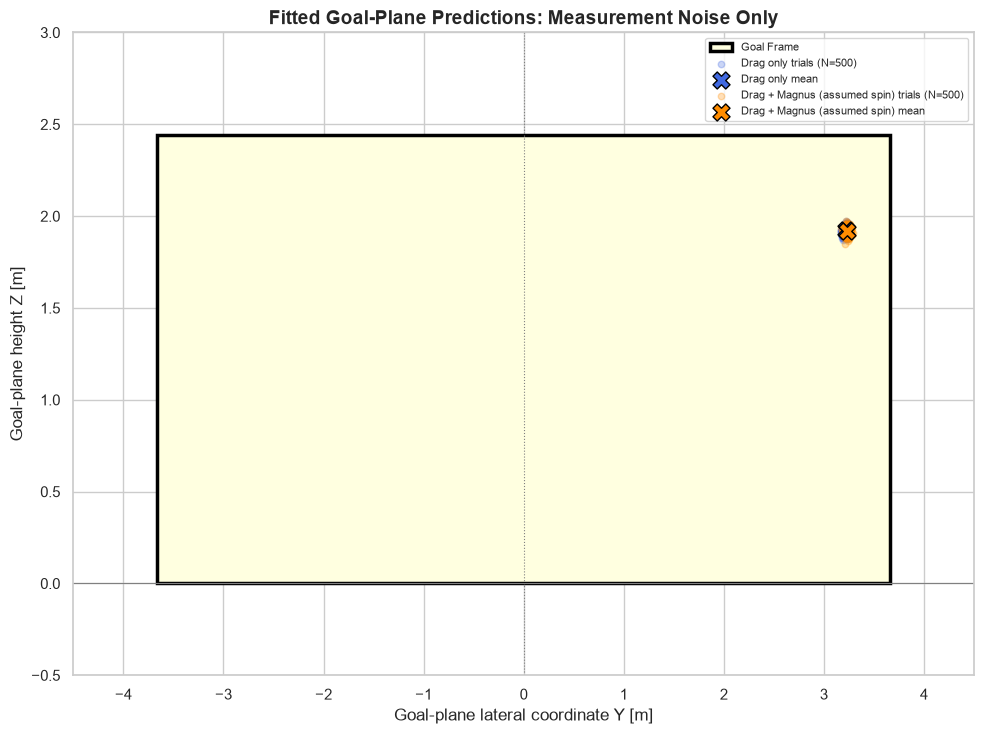

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2
import seaborn as sns
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

sns.set_theme(style="whitegrid")

# IMPROVEMENT NOTES:
# 1. Fit launch velocity to both measured positions for each dynamics model.
# 2. Compare drag-only with drag + assumed Magnus spin.
# 3. Use exact interpolated goal-event states, not the last stored solver step.
# 4. Separate tracking-noise Monte Carlo from exploratory parameter sensitivity.
# The spin and aerodynamic ranges below are assumptions, not measured uncertainties.
# No independent real-kick outcome is provided, so real-world accuracy cannot be measured here.

# --- Physical Constants & Observations ---
m = 0.43
r = 0.11
A = np.pi * r**2
g = 9.81
altitude = 1400.0  # Kathmandu Valley assumption
omega_nominal = np.array([5.0, 10.0, 32.0])  # Assumed spin vector, rad/s
r0 = np.array([0.0, 0.0, 0.11])  # Problem gives this initial point
r1 = np.array([1.50, 0.45, 0.44])
r2 = np.array([2.96, 0.86, 0.74])
dt = 0.05
observation_times = np.array([dt, 2 * dt])
sigma_position = 0.005  # Independent Gaussian coordinate noise, m
n_trials = 500

# --- Aerodynamic Model ---
def get_Cd(v_mag):
    v_crit = 18.0
    return 0.42 - (0.42 - 0.20) / (1.0 + np.exp(-0.5 * (v_mag - v_crit)))


def get_Cl(v_mag, omega_mag):
    if v_mag < 0.1 or omega_mag < 0.1:
        return 0.0
    return 0.18 * np.tanh(2.0 * (omega_mag * r) / v_mag)


def ode_system(t, state, spin_vector, drag_scale):
    x, y, z, vx, vy, vz = state
    velocity = np.array([vx, vy, vz])
    v_mag = np.linalg.norm(velocity)
    omega_mag = np.linalg.norm(spin_vector)
    rho = 1.225 * np.exp(-max(0.0, altitude + z) / 8450.0)
    a_drag = -drag_scale * (rho * A * get_Cd(v_mag) / (2.0 * m)) * v_mag * velocity
    if omega_mag > 0.0 and v_mag > 0.1:
        cl = get_Cl(v_mag, omega_mag)
        a_magnus = (rho * A * r * cl * omega_mag * v_mag / (2.0 * m)) * np.cross(
            spin_vector / omega_mag, velocity / v_mag
        )
    else:
        a_magnus = np.zeros(3)
    acceleration = a_drag + a_magnus + np.array([0.0, 0.0, -g])
    return [vx, vy, vz, *acceleration]


def integrate_to_observations(v0, spin_vector, drag_scale):
    sol = solve_ivp(
        lambda t, state: ode_system(t, state, spin_vector, drag_scale),
        (0.0, observation_times[-1]), np.concatenate((r0, v0)),
        t_eval=observation_times, max_step=0.002, rtol=1e-8, atol=1e-10,
    )
    if not sol.success or sol.y.shape[1] != len(observation_times):
        raise RuntimeError(f"Observation integration failed: {sol.message}")
    return sol.y[:3, :].T


def fit_launch_velocity(r1_observed, r2_observed, spin_vector, drag_scale):
    observed = np.vstack((r1_observed, r2_observed))
    # Three-point finite difference is only the initial guess; fit uses both points.
    initial_guess = (4 * r1_observed - r2_observed - 3 * r0) / (2 * dt)

    def residual(v0):
        return ((integrate_to_observations(v0, spin_vector, drag_scale) - observed) / sigma_position).ravel()

    fit = least_squares(residual, initial_guess, x_scale="jac", max_nfev=100)
    if not fit.success:
        raise RuntimeError(f"Launch-velocity fit failed: {fit.message}")
    predicted = integrate_to_observations(fit.x, spin_vector, drag_scale)
    return fit.x, predicted, observed - predicted


def integrate_to_goal(v0, spin_vector, drag_scale):
    def goal_event(t, state):
        return state[0] - 11.0
    goal_event.terminal = True
    goal_event.direction = 1
    sol = solve_ivp(
        lambda t, state: ode_system(t, state, spin_vector, drag_scale),
        (0.0, 1.0), np.concatenate((r0, v0)), events=goal_event,
        max_step=0.002, rtol=1e-8, atol=1e-10,
    )
    if not sol.success:
        raise RuntimeError(f"Goal integration failed: {sol.message}")
    if len(sol.t_events[0]) == 0:
        return None
    return sol.t_events[0][0], sol.y_events[0][0]


# --- 1. Fit and Compare Drag-Only vs. Drag + Magnus ---
# The spin is not measured: the Magnus case uses the stated assumed vector.
models = {
    "Drag only": np.zeros(3),
    "Drag + Magnus (assumed spin)": omega_nominal,
}
fit_results = {}
print("MODEL FITS TO THE TWO OBSERVED POSITIONS")
print("Fitting 3 launch-velocity components; initial position is treated as exact.")
print("Fit diagnostic tests the observations against the assumed 5 mm noise; it is not real-world validation.")
for model_name, spin_vector in models.items():
    v0_fit, predicted, residuals = fit_launch_velocity(r1, r2, spin_vector, 1.0)
    impact = integrate_to_goal(v0_fit, spin_vector, 1.0)
    rmse = np.sqrt(np.mean(residuals**2))
    chi2_stat = np.sum((residuals / sigma_position) ** 2)
    fit_dof = residuals.size - v0_fit.size
    fit_p_value = chi2.sf(chi2_stat, fit_dof)
    fit_results[model_name] = {"spin": spin_vector, "v0": v0_fit, "predicted": predicted, "residuals": residuals, "rmse": rmse, "chi2": chi2_stat, "dof": fit_dof, "p_value": fit_p_value, "impact": impact}
    print(f"\n{model_name}:")
    print(f"  Fitted launch velocity: {v0_fit.round(4)} m/s")
    print(f"  Observed - fitted residuals (mm):\n{(1000 * residuals).round(2)}")
    print(f"  Coordinate RMSE: {1000 * rmse:.2f} mm (assumed sigma = {1000*sigma_position:.1f} mm)")
    print(f"  Noise-only fit diagnostic: chi-square={chi2_stat:.2f}, dof={fit_dof}, p={fit_p_value:.4f}")
    if fit_p_value < 0.05:
        print("  Flag: residuals are larger than expected from 5 mm Gaussian measurement noise alone.")
    if impact is None:
        print("  No forward crossing of the goal plane was found.")
    else:
        t_hit, hit_state = impact
        print(f"  Exact goal crossing: t={t_hit:.5f} s, y={hit_state[1]:.3f} m, z={hit_state[2]:.3f} m")

# --- 2. Synthetic Recovery Check ---
# This is a self-consistency test, not independent validation of the physics.
truth_v0 = fit_results["Drag + Magnus (assumed spin)"]["v0"]
synthetic_points = integrate_to_observations(truth_v0, omega_nominal, 1.0)
recovered_v0, _, _ = fit_launch_velocity(synthetic_points[0], synthetic_points[1], omega_nominal, 1.0)
truth_impact = integrate_to_goal(truth_v0, omega_nominal, 1.0)
recovered_impact = integrate_to_goal(recovered_v0, omega_nominal, 1.0)
if truth_impact is None or recovered_impact is None:
    raise RuntimeError("Synthetic recovery check failed to reach the goal plane.")
print("\nSYNTHETIC RECOVERY (self-consistency only)")
print(f"  Launch-velocity recovery error: {np.linalg.norm(recovered_v0 - truth_v0):.6g} m/s")
print(f"  Crossing recovery error: dy={recovered_impact[1][1] - truth_impact[1][1]:.6g} m, dz={recovered_impact[1][2] - truth_impact[1][2]:.6g} m")

# --- 3. Measurement-Noise Monte Carlo ---
# Only r1/r2 are perturbed: the problem specifies r0 as the initial condition.
# These intervals quantify the assumed tracking noise, not model uncertainty
# or real-world prediction accuracy.
rng = np.random.default_rng(42)
mc_results = {}
print(f"\n{n_trials}-TRIAL MEASUREMENT-NOISE PROPAGATION (sigma={1000*sigma_position:.1f} mm)")
for model_name, spin_vector in models.items():
    trial_t, trial_y, trial_z = [], [], []
    for _ in range(n_trials):
        r1_noisy = r1 + rng.normal(0.0, sigma_position, size=3)
        r2_noisy = r2 + rng.normal(0.0, sigma_position, size=3)
        v0_noisy, _, _ = fit_launch_velocity(r1_noisy, r2_noisy, spin_vector, 1.0)
        impact = integrate_to_goal(v0_noisy, spin_vector, 1.0)
        if impact is None:
            raise RuntimeError(f"A {model_name} Monte Carlo trial did not cross the goal plane.")
        t_hit, hit_state = impact
        trial_t.append(t_hit)
        trial_y.append(hit_state[1])
        trial_z.append(hit_state[2])
    result = {"t": np.asarray(trial_t), "y": np.asarray(trial_y), "z": np.asarray(trial_z)}
    mc_results[model_name] = result
    y_ci = np.percentile(result["y"], [2.5, 97.5])
    z_ci = np.percentile(result["z"], [2.5, 97.5])
    print(f"\n{model_name}:")
    print(f"  Flight time mean +/- SD: {np.mean(result['t']):.4f} +/- {np.std(result['t'], ddof=1):.4f} s")
    print(f"  Y mean +/- SD: {np.mean(result['y']):.3f} +/- {np.std(result['y'], ddof=1):.3f} m")
    print(f"  Z mean +/- SD: {np.mean(result['z']):.3f} +/- {np.std(result['z'], ddof=1):.3f} m")
    print(f"  Empirical 95% interval Y: [{y_ci[0]:.3f}, {y_ci[1]:.3f}] m")
    print(f"  Empirical 95% interval Z: [{z_ci[0]:.3f}, {z_ci[1]:.3f}] m")

# --- 4. Exploratory Model-Parameter Sensitivity ---
# Illustrative scenarios only: spin direction fixed, magnitude scaled 0--2x;
# drag acceleration scaled by 0.8, 1.0, and 1.2. Not statistical confidence limits.
spin_scales = [0.0, 0.5, 1.0, 1.5, 2.0]
drag_scales = [0.8, 1.0, 1.2]
sensitivity = []
print("\nPARAMETER SENSITIVITY (illustrative assumptions, not a confidence interval)")
print("Spin x | Drag x | Fit RMSE mm | Time s | Goal y m | Goal z m")
for spin_scale in spin_scales:
    for drag_scale in drag_scales:
        spin_vector = spin_scale * omega_nominal
        v0_fit, _, residuals = fit_launch_velocity(r1, r2, spin_vector, drag_scale)
        impact = integrate_to_goal(v0_fit, spin_vector, drag_scale)
        if impact is None:
            raise RuntimeError(f"Sensitivity scenario failed: spin={spin_scale}, drag={drag_scale}")
        t_hit, hit_state = impact
        row = (spin_scale, drag_scale, np.sqrt(np.mean(residuals**2)), t_hit, hit_state[1], hit_state[2])
        sensitivity.append(row)
        print(f"{spin_scale:6.1f} | {drag_scale:6.1f} | {1000*row[2]:11.2f} | {t_hit:6.4f} | {hit_state[1]:8.3f} | {hit_state[2]:8.3f}")
sensitivity = np.asarray(sensitivity)
print("Scenario envelope (not probabilistic):")
print(f"  Y: [{sensitivity[:, 4].min():.3f}, {sensitivity[:, 4].max():.3f}] m")
print(f"  Z: [{sensitivity[:, 5].min():.3f}, {sensitivity[:, 5].max():.3f}] m")

# --- 5. Compare Measurement-Noise Distributions ---
fig, ax = plt.subplots(figsize=(10, 7.5))
goal_rect = plt.Rectangle((-3.66, 0.0), 7.32, 2.44, linewidth=2.5, edgecolor="black", facecolor="lightyellow", label="Goal Frame", zorder=1)
ax.add_patch(goal_rect)
colors = {"Drag only": "royalblue", "Drag + Magnus (assumed spin)": "darkorange"}
for model_name, result in mc_results.items():
    ax.scatter(result["y"], result["z"], color=colors[model_name], alpha=0.28, s=22, label=f"{model_name} trials (N={n_trials})", zorder=2)
    ax.scatter(np.mean(result["y"]), np.mean(result["z"]), color=colors[model_name], edgecolor="black", marker="X", s=150, zorder=4, label=f"{model_name} mean")
ax.set_title("Fitted Goal-Plane Predictions: Measurement Noise Only", fontsize=14, fontweight="bold")
ax.set_xlabel("Goal-plane lateral coordinate Y [m]")
ax.set_ylabel("Goal-plane height Z [m]")
ax.set_xlim(-4.5, 4.5)
ax.set_ylim(-0.5, 3.0)
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8, linestyle=":")
ax.legend(loc="upper right", frameon=True, fontsize=8)
plt.tight_layout()
plt.show()